# Generalized plane stress
Thin plates loaded in their plane are often modelled in 2d, assuming plane stress, i.e.
$\sigma_{33} = 0$. For a nonlinear 3d material model, this requires local iterations in each
quadrature point to find the out-of-plane strain, $\varepsilon_{33}$, giving $\sigma_{33} = 0$.
In this tutorial, we instead consider *generalized plane stress*, where the out-of-plane strain is
a single global unknown (constant in the domain), and the out-of-plane stress is only zero on average,
$$
\int_\Omega \sigma_{33}\ \mathrm{d}\Omega = 0
$$
This plane stress condition is fulfilled during the global (Newton) iterations, together with the equilibrium
equations, and the 3d material model can be used directly. The strain in the plate is
$$
\boldsymbol{\varepsilon} = \left[\boldsymbol{u}\otimes\nabla\right]^\mathrm{sym} + \varepsilon_{33}\ \boldsymbol{e}_3\otimes\boldsymbol{e}_3
$$
where the 2d displacement field, $\boldsymbol{u}$, and its gradient are lifted to 3d.
The weak form, without external loads, becomes
$$
\int_\Omega \left[\left[\boldsymbol{\delta u}\otimes\nabla\right]^\mathrm{sym} + \delta\varepsilon_{33}\ \boldsymbol{e}_3\otimes\boldsymbol{e}_3\right] : \boldsymbol{\sigma}\ \mathrm{d}\Omega = 0
$$
for all $\boldsymbol{\delta u}$ and $\delta\varepsilon_{33}$. Considering $\varepsilon_{33}$ as an
additional degree of freedom of the displacement field, with a base function that has a zero value and the
gradient $\boldsymbol{e}_3\otimes\boldsymbol{e}_3$, this is the standard weak form of mechanical equilibrium.
Hence, we can use an unmodified element routine for a 3d material, by *attaching* the algebraic variable
$\varepsilon_{33}$ to the displacement field, see Attached variables.

## Out-of-plane cell values
The values type below wraps the `CellValues` for the in-plane problem and lifts the shape values and
gradients to 3d. It adds one base function with a zero value and the out-of-plane gradient,
$\boldsymbol{e}_3$ for scalar fields and $\boldsymbol{e}_3\otimes\boldsymbol{e}_3$ for vector fields.
The derived accessors, such as `shape_symmetric_gradient` and `function_symmetric_gradient`, are then given by
`Ferrite`. We also lift the coordinates given to the element routine, `getcoordinates(buffer)`, to 3d,
by overloading `FerriteAssembly.routine_coordinates`. This is not required in this tutorial, but makes
the element routine see a consistent 3d problem.

In [1]:
using Ferrite, FerriteAssembly
import MaterialModelsBase as MMB
import MechanicalMaterialModels as MMM
import CairoMakie as CM

struct OutOfPlaneCellValues{CV <: CellValues} <: Ferrite.AbstractCellValues
    cv::CV                      # CellValues for the in-plane problem
    x::Vector{Vec{3, Float64}}  # Cell coordinates lifted to 3d
end
function OutOfPlaneCellValues(cv::CellValues)
    return OutOfPlaneCellValues(cv, zeros(Vec{3, Float64}, Ferrite.getngeobasefunctions(cv)))
end

# Lifting of 2d tensors to 3d
lift3d(v::Number) = v
lift3d(v::Vec{2, T}) where {T} = Vec{3, T}((v[1], v[2], zero(T)))
lift3d(t::Tensor{2, 2, T}) where {T} = Tensor{2, 3, T}((i, j) -> (i ≤ 2 && j ≤ 2) ? t[i, j] : zero(T))

# Gradient of the out-of-plane base function, for scalar and vector fields
out_of_plane_gradient(::Number) = Vec{3}((0.0, 0.0, 1.0))
out_of_plane_gradient(::Vec) = Tensor{2, 3}((i, j) -> (i == 3 && j == 3) ? 1.0 : 0.0)

# The required accessors
Ferrite.getnbasefunctions(v::OutOfPlaneCellValues) = getnbasefunctions(v.cv) + 1
Ferrite.getnquadpoints(v::OutOfPlaneCellValues) = getnquadpoints(v.cv)
Ferrite.getdetJdV(v::OutOfPlaneCellValues, q_point::Int) = getdetJdV(v.cv, q_point)
Ferrite.getngeobasefunctions(v::OutOfPlaneCellValues) = Ferrite.getngeobasefunctions(v.cv)
Ferrite.geometric_value(v::OutOfPlaneCellValues, q_point::Int, i::Int) = Ferrite.geometric_value(v.cv, q_point, i)

function Ferrite.reinit!(v::OutOfPlaneCellValues, cell::Union{Nothing, Ferrite.AbstractCell}, x::AbstractVector{<:Vec})
    v.x .= lift3d.(x)
    return reinit!(v.cv, cell, x)
end

function Ferrite.shape_value(v::OutOfPlaneCellValues, q_point::Int, i::Int)
    N1 = lift3d(shape_value(v.cv, q_point, 1)) # Ensure the same type for all base functions
    return i ≤ getnbasefunctions(v.cv) ? lift3d(shape_value(v.cv, q_point, i)) : zero(N1)
end

function Ferrite.shape_gradient(v::OutOfPlaneCellValues, q_point::Int, i::Int)
    i ≤ getnbasefunctions(v.cv) && return lift3d(shape_gradient(v.cv, q_point, i))
    return out_of_plane_gradient(shape_value(v.cv, q_point, 1))
end

FerriteAssembly.routine_coordinates(v::OutOfPlaneCellValues, ::AbstractVector{<:Vec}) = v.x;

We can check that the accessors used by typical element routines work, and don't allocate,

In [2]:
qr = QuadratureRule{RefQuadrilateral}(2)
ip = Lagrange{RefQuadrilateral, 1}()^2
cv_oop = OutOfPlaneCellValues(CellValues(qr, ip))
let grid = generate_grid(Quadrilateral, (1, 1))
    FerriteAssembly.check_values_interface(cv_oop, getcells(grid, 1), getcoordinates(grid, 1))
end

true

## Problem setup
We consider a tapered plate, loaded in tension by prescribing the displacement of the right edge.
Symmetry conditions are applied on the left and bottom edges.

In [3]:
L, H = (10.0, 2.0)
grid = generate_grid(Quadrilateral, (40, 8), Vec((0.0, 0.0)), Vec((L, H)))
transform_coordinates!(grid, x -> Vec((x[1], x[2] * (1 - 0.5 * x[1] / L))))

Grid{2, Quadrilateral, Float64} with 320 Quadrilateral cells and 369 nodes

The `DofHandler` contains the displacement field, `:u`, and the out-of-plane strain, `:ϵ33`, as a scalar
algebraic variable.

In [4]:
dh = DofHandler(grid)
add!(dh, :u, ip)
add!(dh, :ϵ33, AlgebraicVariable())
close!(dh);

For the boundary conditions, the displacement of the right edge, `Δu`, is ramped during the load steps.
For comparison, we will also solve the plane strain problem, by prescribing `ϵ33 = 0` with an `AffineConstraint`
without master degrees of freedom.

In [5]:
function create_constrainthandler(dh, Δu; plane_strain = false)
    ch = ConstraintHandler(dh)
    add!(ch, Dirichlet(:u, getfacetset(dh.grid, "left"), Returns(0.0), 1))
    add!(ch, Dirichlet(:u, getfacetset(dh.grid, "bottom"), Returns(0.0), 2))
    add!(ch, Dirichlet(:u, getfacetset(dh.grid, "right"), (x, t) -> Δu * t, 1))
    if plane_strain
        add!(ch, AffineConstraint(only(algebraic_dofs(dh, :ϵ33)), Pair{Int, Float64}[], 0.0))
    end
    close!(ch)
    return ch
end;

The reaction force is the sum of the residual for the degrees of freedom on the right edge, in the loading direction.

In [6]:
function right_edge_dofs(dh)
    ch = ConstraintHandler(dh)
    add!(ch, Dirichlet(:u, getfacetset(dh.grid, "right"), Returns(0.0), 1))
    close!(ch)
    return ch.prescribed_dofs
end;

We use an elasto-plastic material model from
[`MechanicalMaterialModels.jl`](https://github.com/KnutAM/MechanicalMaterialModels.jl)

In [7]:
material = MMM.Plastic(;
    elastic = MMM.LinearElastic(; E = 210.0e3, ν = 0.3),
    yield = 300.0,
    isotropic = MMM.Voce(; Hiso = 10.0e3, κ∞ = 200.0),
    kinematic = MMM.ArmstrongFrederick(; Hkin = 20.0e3, β∞ = 100.0),
);

The domain for the generalized plane stress problem uses the 3d `material` and the out-of-plane
cell values, with `:ϵ33` attached to `:u`. The element routine for a `MaterialModelsBase.AbstractMaterial`
(see MaterialModelsBase) is then used unchanged, now in 3d.

In [8]:
domain_gps = DomainSpec(dh, material, cv_oop;
    algebraic_variables = (FerriteAssembly.AttachAlgebraic(:ϵ33 => :u),));

## Solving the problem
We solve the problem with Newton iterations, updating all unknowns, including `:ϵ33`, together.
The coupling between `:ϵ33` and `:u` must be included in the sparsity pattern, see
`FerriteAssembly.algebraic_couplings`. The residual for `:ϵ33` is $\int_\Omega \sigma_{33}\ \mathrm{d}\Omega$,
so the plane stress condition is fulfilled on average when the Newton iterations have converged.

To avoid large strains close to the right edge in the first iteration of each load step, the increments of
the prescribed displacements are applied in the first iteration, using the tangent stiffness from the
previous step. Since the prescribed values are linear in time, `update!(ch, t - t_old)` gives these increments.

In [9]:
function solve(domain, dh; ϵ33_dofs = Int[], plane_strain = false, Δu = 0.1, num_steps = 40, tolerance = 1.0e-8, maxiter = 20)
    buffer = setup_domainbuffer(domain)
    ch = create_constrainthandler(dh, Δu; plane_strain)
    right_dofs = right_edge_dofs(dh)
    K = allocate_matrix(dh, ch; algebraic_couplings = FerriteAssembly.algebraic_couplings(buffer))
    r = zeros(ndofs(dh))
    a = zeros(ndofs(dh))
    displacement = [0.0]
    force = [0.0]
    ϵ33 = [0.0]
    t_old = 0.0
    for t in range(0, 1, num_steps + 1)[2:end]
        update!(ch, t - t_old)
        reaction = 0.0
        for i in 1:maxiter
            assembler = start_assemble(K, r)
            work!(assembler, buffer; a)
            reaction = sum(r[right_dofs])
            if i == 1 # Apply the increments of the prescribed values
                r .*= -1
                apply!(K, r, ch)
                a .+= K \ r
            else
                apply_zero!(K, r, ch)
                norm(r) < tolerance * max(1.0, abs(reaction)) && break
                i == maxiter && error("Did not converge")
                a .-= K \ r
            end
        end
        update_states!(buffer)
        push!(displacement, Δu * t)
        push!(force, reaction)
        push!(ϵ33, isempty(ϵ33_dofs) ? NaN : a[only(ϵ33_dofs)])
        t_old = t
    end
    return displacement, force, ϵ33
end;

Generalized plane stress, where we also save the out-of-plane strain

In [10]:
displacement, force_gps, ϵ33_gps = solve(domain_gps, dh; ϵ33_dofs = algebraic_dofs(dh, :ϵ33));

Plane strain, using the same domain, but with `:ϵ33` prescribed to zero

In [11]:
_, force_pe, _ = solve(domain_gps, dh; plane_strain = true);

For comparison, we also solve the standard plane stress problem, where the material model is
solved such that $\sigma_{33} = 0$ in each quadrature point. For this case, we use a `DofHandler`
without `:ϵ33`, the ordinary `CellValues`, and the `ReducedStressState` wrapper from `MaterialModelsBase`.

In [12]:
dh_ps = DofHandler(grid)
add!(dh_ps, :u, ip)
close!(dh_ps)
domain_ps = DomainSpec(dh_ps, MMB.ReducedStressState(MMB.PlaneStress(), material), CellValues(qr, ip))
_, force_ps, _ = solve(domain_ps, dh_ps);

## Results
The generalized plane stress solution is stiffer than the plane stress solution, since the out-of-plane strain is
constant and the out-of-plane stress is only zero on average. We first check that this expectation holds

In [13]:
all(force_ps[2:end] .< force_gps[2:end] .< force_pe[2:end])

true

Before also plotting the response to see this graphically

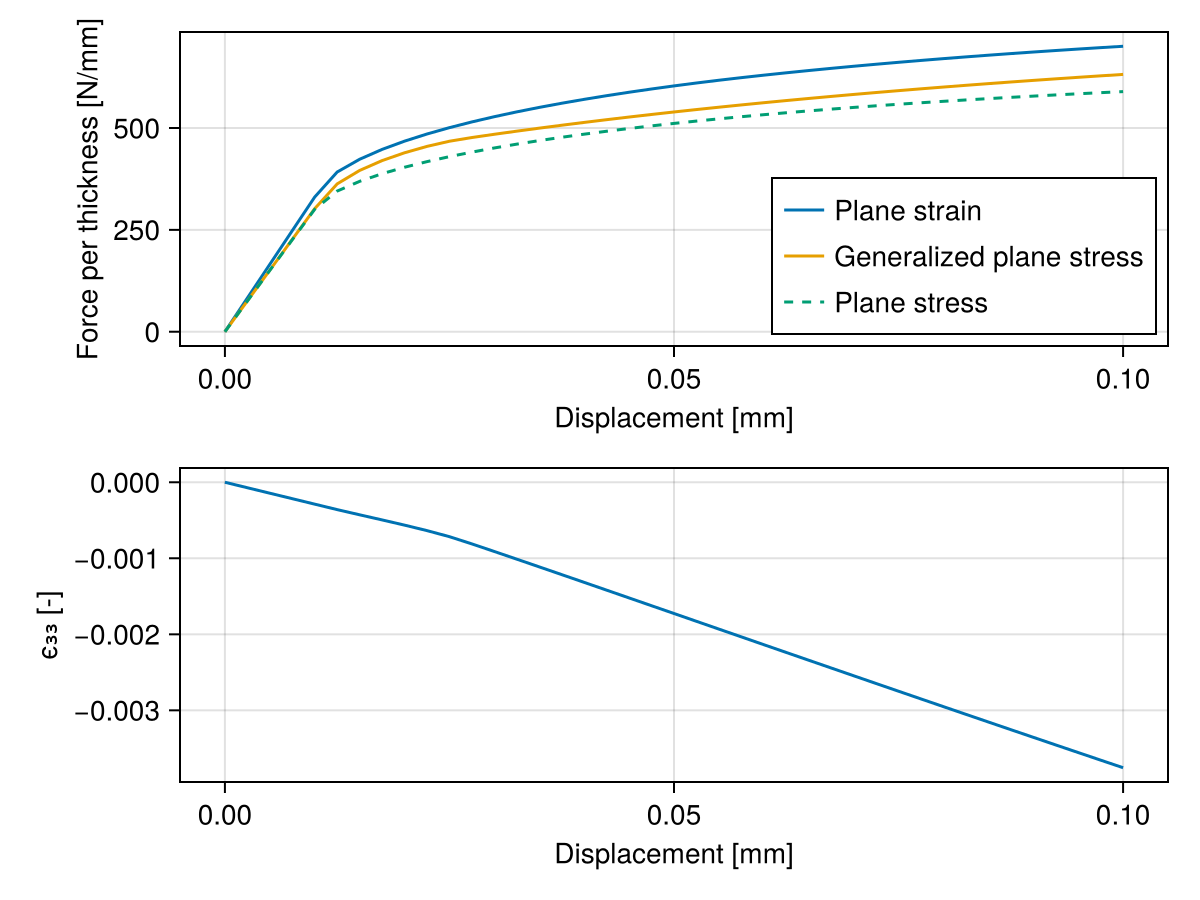

In [14]:
fig = CM.Figure()
ax_f = CM.Axis(fig[1, 1]; xlabel = "Displacement [mm]", ylabel = "Force per thickness [N/mm]")
CM.lines!(ax_f, displacement, force_pe; label = "Plane strain")
CM.lines!(ax_f, displacement, force_gps; label = "Generalized plane stress")
CM.lines!(ax_f, displacement, force_ps; label = "Plane stress", linestyle = :dash)
CM.axislegend(ax_f; position = :rb)
ax_e = CM.Axis(fig[2, 1]; xlabel = "Displacement [mm]", ylabel = "ϵ₃₃ [-]")
CM.lines!(ax_e, displacement, ϵ33_gps)
fig

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*